In [ ]:
!pip install ultralytics

In [29]:
import kagglehub
import os
import matplotlib.pyplot as plt
import numpy as np
from ultralytics import YOLO
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import cv2
from google.colab.patches import cv2_imshow
import pandas as pd

import warnings
warnings.filterwarnings('ignore')

In [3]:
path = kagglehub.dataset_download("bmadushanirodrigo/fracture-multi-region-x-ray-data")

print("Path to dataset files:", path)

100%|██████████| 481M/481M [00:05<00:00, 88.0MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/bmadushanirodrigo/fracture-multi-region-x-ray-data/versions/2


In [4]:
path

'/root/.cache/kagglehub/datasets/bmadushanirodrigo/fracture-multi-region-x-ray-data/versions/2'

In [5]:
os.listdir(path)

['Bone_Fracture_Binary_Classification', 'README.dataset.txt']

In [6]:
grand_folder = os.path.join(path, 'Bone_Fracture_Binary_Classification')
print(grand_folder)

/root/.cache/kagglehub/datasets/bmadushanirodrigo/fracture-multi-region-x-ray-data/versions/2/Bone_Fracture_Binary_Classification


In [7]:
data = os.path.join(grand_folder, 'Bone_Fracture_Binary_Classification')

In [8]:
os.listdir(data)

['val', 'test', 'train']

In [11]:
model = YOLO('yolo11s-cls.pt')

In [12]:
result = model.train(
    data = data,
    epochs = 5,
    imgsz = 224,
    batch = 96,
    name = 'yolo11s_bone_classification'
)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=96, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/root/.cache/kagglehub/datasets/bmadushanirodrigo/fracture-multi-region-x-ray-data/versions/2/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=

In [24]:
prediction = model.val(
    data = data,
    split = 'test'
)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-cls summary (fused): 47 layers, 5,436,690 parameters, 0 gradients, 12.1 GFLOPs
train: /root/.cache/kagglehub/datasets/bmadushanirodrigo/fracture-multi-region-x-ray-data/versions/2/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/train... found 9246 images in 2 classes ✅ 
val: /root/.cache/kagglehub/datasets/bmadushanirodrigo/fracture-multi-region-x-ray-data/versions/2/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/val... found 829 images in 2 classes ✅ 
test: /root/.cache/kagglehub/datasets/bmadushanirodrigo/fracture-multi-region-x-ray-data/versions/2/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/test... found 506 images in 2 classes ✅ 
test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2626.7±555.1 MB/s, size: 1027.5 KB)
test: Scanning /root/.cache/kagglehub/datasets/bmadushanirodrigo/fracture-multi-region-x-ray-data/vers

## Prediction matrics

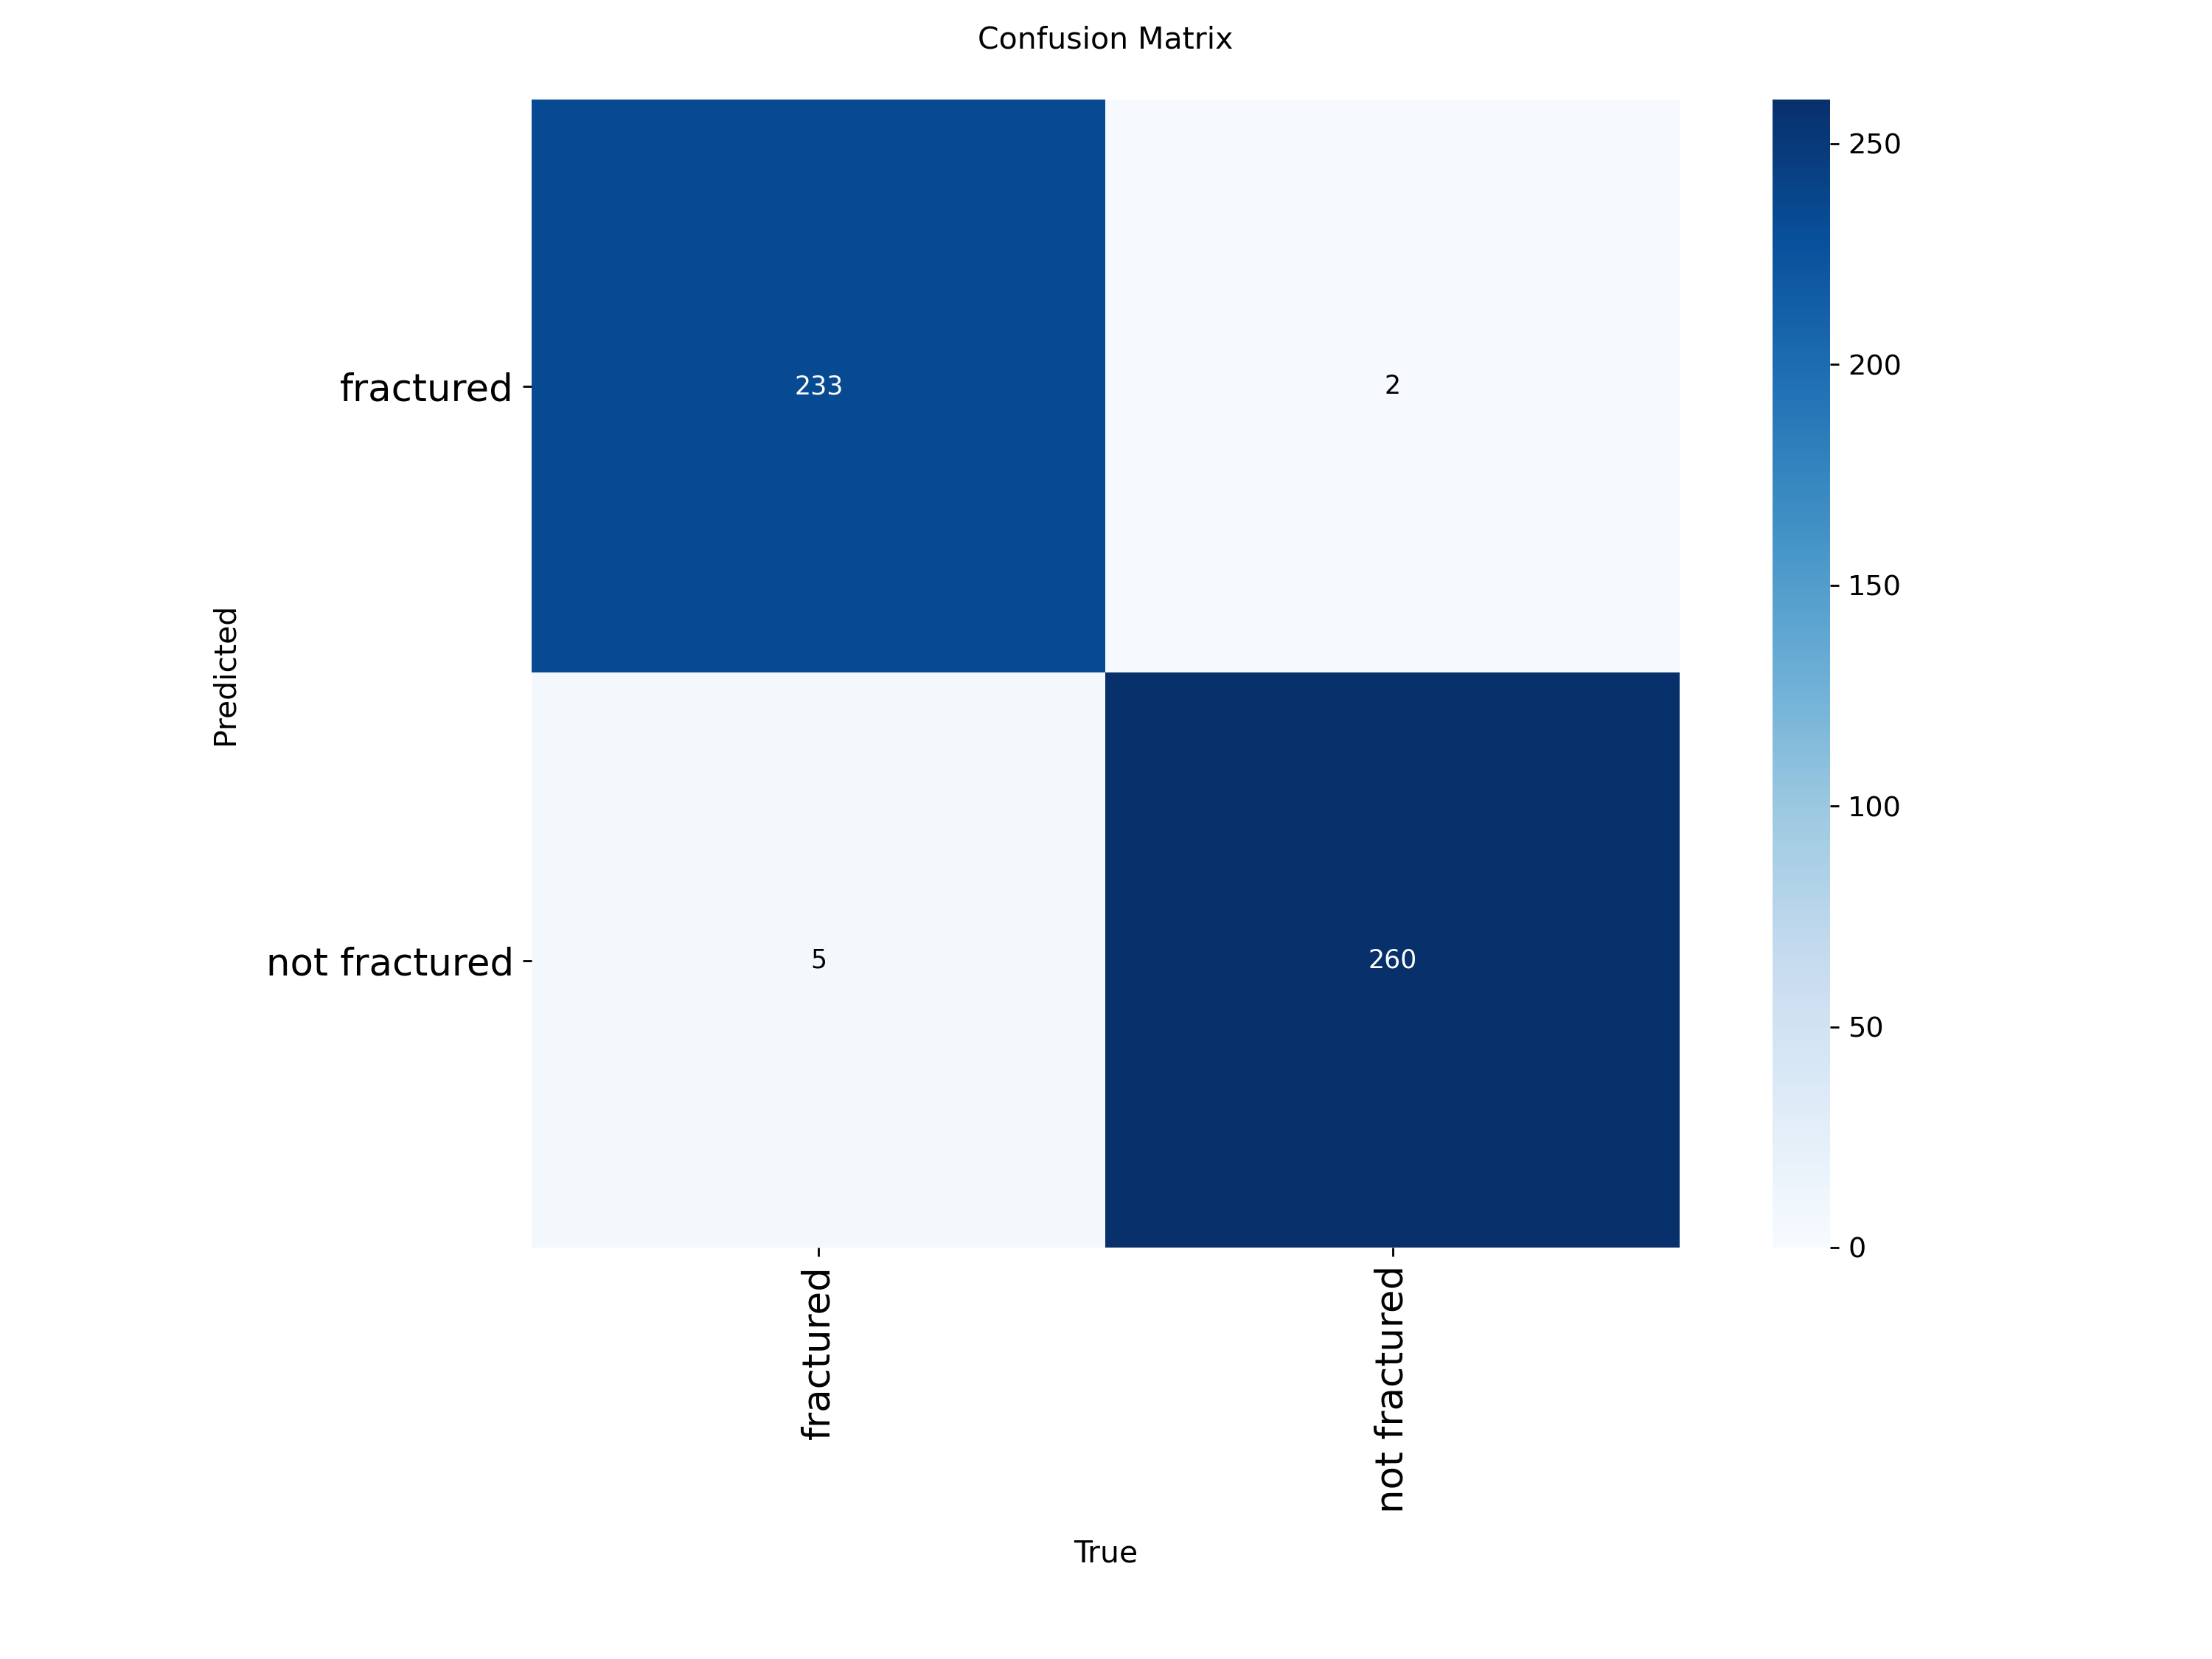

In [ ]:
cm_image_path = "/content/runs/classify/val/confusion_matrix.png"
img = cv2.imread(cm_image_path)
cv2_imshow(img)

## Train matrics

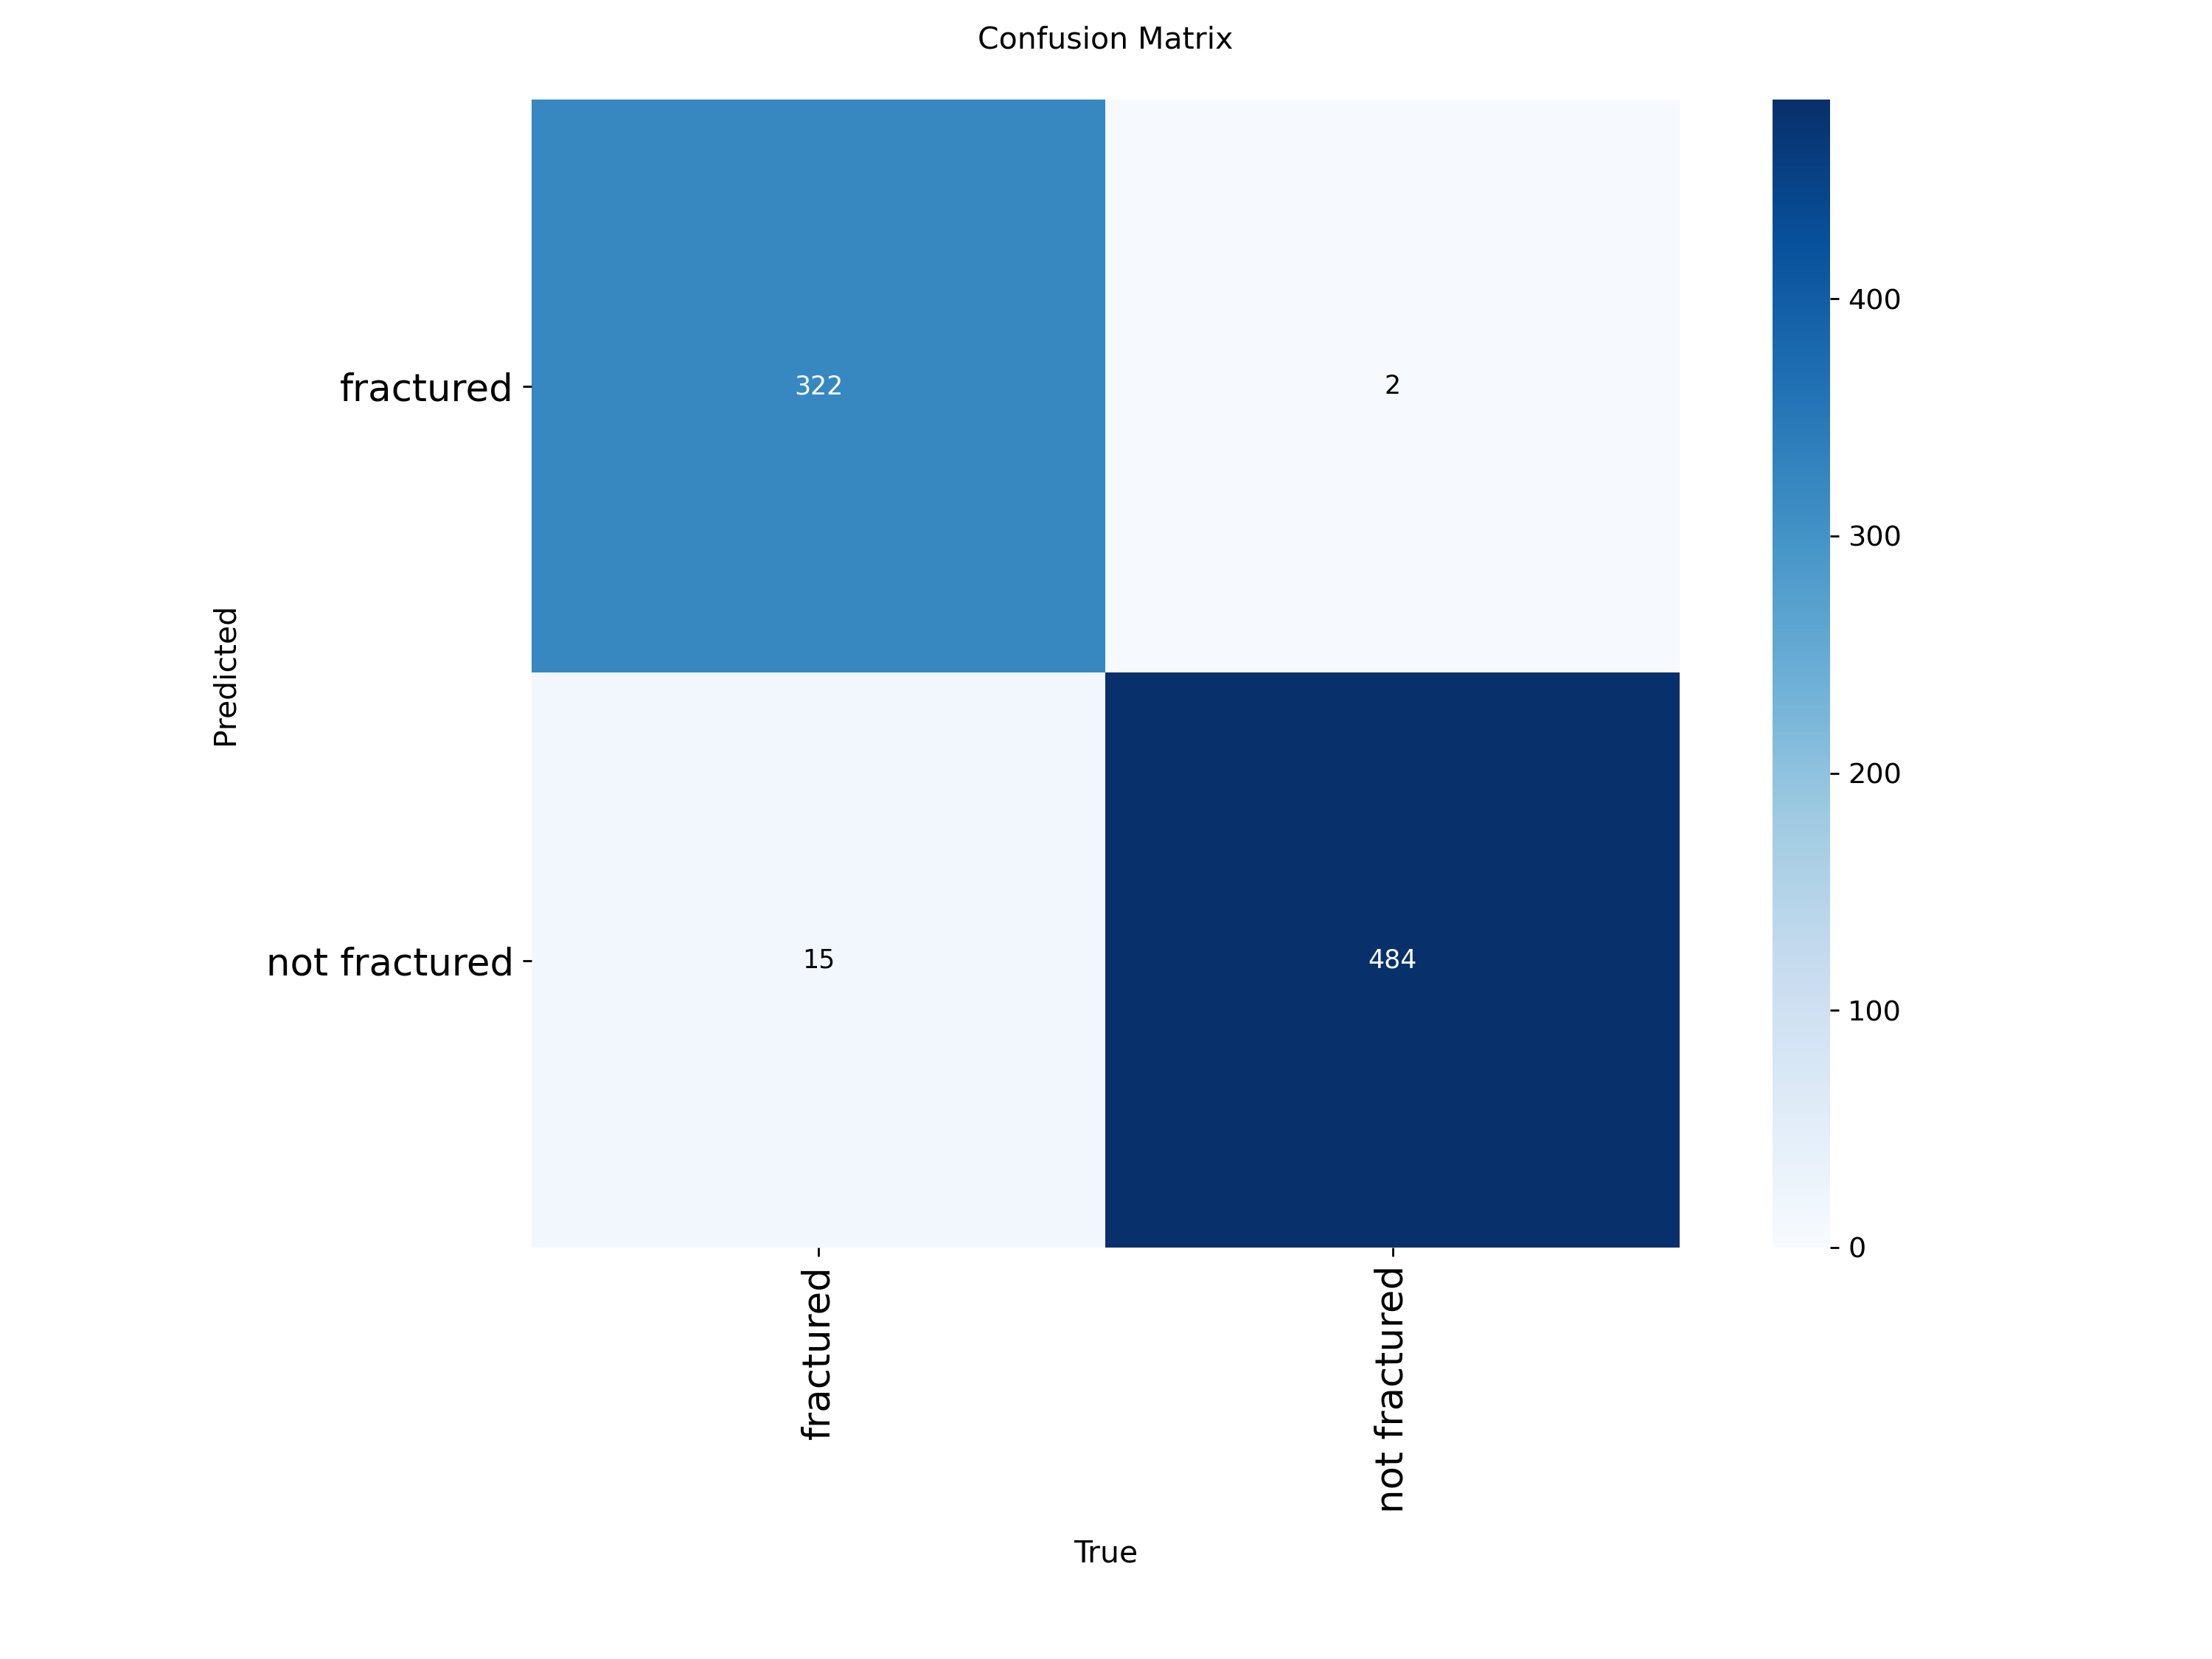

In [ ]:
cm_image_path = '/content/runs/classify/yolo11s_bone_classification/confusion_matrix.png'
img = cv2.imread(cm_image_path)
cv2_imshow(img)

In [ ]:
result_df = pd.read_csv(r'/content/runs/classify/yolo11s_bone_classification/results.csv')

In [31]:
result_df

,epoch,time,train/loss,metrics/accuracy_top1,metrics/accuracy_top5,val/loss,lr/pg0,lr/pg1,lr/pg2
0,1,73.3163,0.30390,0.91859,1,0.24801,0.000550,0.000550,0.000550
1,2,146.7440,0.14222,0.86513,1,0.38470,0.000887,0.000887,0.000887
2,3,215.2360,0.11821,0.94897,1,0.15178,0.001003,0.001003,0.001003
3,4,283.2280,0.07970,0.97448,1,0.06328,0.000677,0.000677,0.000677
4,5,351.9010,0.03313,0.97934,1,0.05594,0.000347,0.000347,0.000347


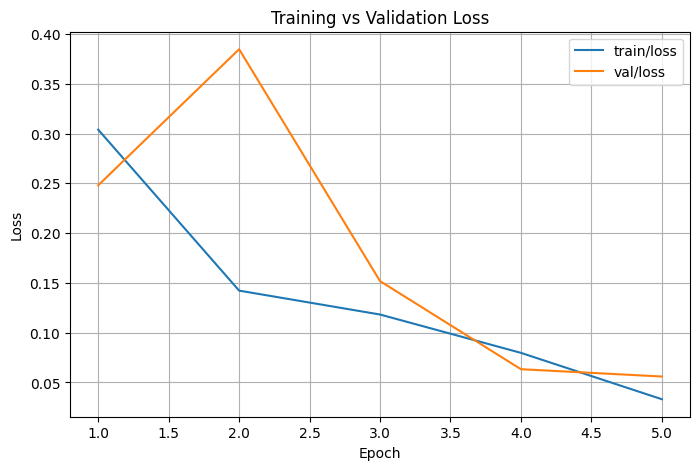

In [36]:
result_df.plot(x='epoch', y=['train/loss', 'val/loss'], figsize=(8, 5))
plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.show()

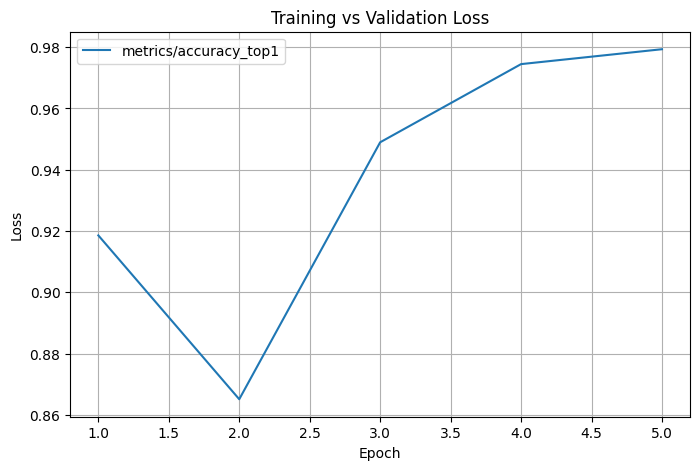

In [39]:
result_df.plot(x='epoch', y = 'metrics/accuracy_top1', figsize=(8, 5))
plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.show()